In [1]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

import pickle, os
import pandas as pd
import numpy as np
import itertools
import seaborn as sns
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             confusion_matrix, roc_auc_score,
                             balanced_accuracy_score, classification_report)
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from joblib import Parallel, delayed
from sklearn.impute import SimpleImputer

In [2]:
with open('/kaggle/input/notebooks/matildeteixeira/wesad-preprocess/processed_data.pkl', 'rb') as f:
    data = pickle.load(f)

df           = data['df']
X            = data['X']
y            = data['y']
groups       = data['groups']
feature_cols = data['feature_cols']

logo  = LeaveOneGroupOut()
folds = list(logo.split(X, y, groups))
X_vals      = X.values
y_vals      = y.values

print(df.shape)
print(y.value_counts())

(27543, 139)
label
0    17577
1     9966
Name: count, dtype: int64


In [3]:
combos_l1l2 = list(itertools.product(
    [0.001, 0.01, 0.1, 1.0],
    ['l1', 'l2'],
    [1e-3],
))
combos_elastic = list(itertools.product(
    [0.001, 0.01, 0.1, 1.0],
    [1e-3],
    [0.3, 0.5, 0.7],
))
all_params_logreg = (
    [{'C': c, 'penalty': p, 'solver': 'saga', 'max_iter': 5000, 'tol': t, 'random_state': 42}
     for c, p, t in combos_l1l2]
  + [{'C': c, 'penalty': 'elasticnet', 'solver': 'saga', 'max_iter': 5000, 'tol': t, 'l1_ratio': r, 'random_state': 42}
     for c, t, r in combos_elastic]
)

In [4]:
def run_combo_logreg(params):
    fold_results = []
    for train_idx, test_idx in folds:
        X_train, X_test = X_vals[train_idx], X_vals[test_idx]
        y_train, y_test = y_vals[train_idx], y_vals[test_idx]

        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='median')
        X_train = scaler.fit_transform(X_train)
        X_test  = scaler.transform(X_test)
        X_train = imputer.fit_transform(X_train)
        X_test  = imputer.transform(X_test)

        smote = SMOTE(random_state=42)
        X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

        try:
            model_params = {k: v for k, v in params.items()
                if not (k == 'l1_ratio' and params.get('penalty') != 'elasticnet')}
            model = LogisticRegression(**model_params)
            model.fit(X_train_sm, y_train_sm)
            y_pred = model.predict(X_test)
            y_prob = model.predict_proba(X_test)[:, 1]
            fold_results.append({
                'accuracy': accuracy_score(y_test, y_pred),
                'f1':       f1_score(y_test, y_pred, zero_division=0, average='weighted'),
                'recall':   recall_score(y_test, y_pred, zero_division=0, average='weighted'),
                'roc_auc':  roc_auc_score(y_test, y_prob),
                'bal_acc':  balanced_accuracy_score(y_test, y_pred),
                'cm':       confusion_matrix(y_test, y_pred),
                'y_test':   y_test,
                'y_pred':   y_pred,
                'y_prob':   y_prob,
            })
        except Exception:
            continue

    if not fold_results:
        return None

    return {
        'params':   params,
        'f1':       np.mean([r['f1']       for r in fold_results]),
        'accuracy': np.mean([r['accuracy'] for r in fold_results]),
        'recall':   np.mean([r['recall']   for r in fold_results]),
        'roc_auc':  np.mean([r['roc_auc']  for r in fold_results]),
        'bal_acc':  np.mean([r['bal_acc']  for r in fold_results]),
        'f1_std':   np.std([r['f1']        for r in fold_results]),
        'cm':       np.sum([r['cm']        for r in fold_results], axis=0),
        'y_test':   np.concatenate([r['y_test'] for r in fold_results]),
        'y_pred':   np.concatenate([r['y_pred'] for r in fold_results]),
        'y_prob':   np.concatenate([r['y_prob'] for r in fold_results]),
    }

print(f"Total combinações: {len(all_params_logreg)} | Folds: {len(folds)}")
all_results_logreg = Parallel(n_jobs=-1, prefer='processes')(
    delayed(run_combo_logreg)(params) for params in all_params_logreg
)
all_results_logreg = [r for r in all_results_logreg if r is not None]
best_logreg = max(all_results_logreg, key=lambda x: x['f1'])

Total combinações: 20 | Folds: 15



AVALIAÇÃO FINAL DETALHADA
              precision    recall  f1-score   support

           0       0.90      0.78      0.83     17577
           1       0.69      0.84      0.76      9966

    accuracy                           0.80     27543
   macro avg       0.79      0.81      0.80     27543
weighted avg       0.82      0.80      0.81     27543

ROC-AUC:                      0.948
Balanced Accuracy:            0.808
Desvio Padrão F1 entre Folds: 0.196

Melhores parâmetros: {'C': 0.001, 'penalty': 'l1', 'solver': 'saga', 'max_iter': 5000, 'tol': 0.001, 'random_state': 42}
Melhor F1:           0.789
Accuracy:            0.802
Recall:              0.802


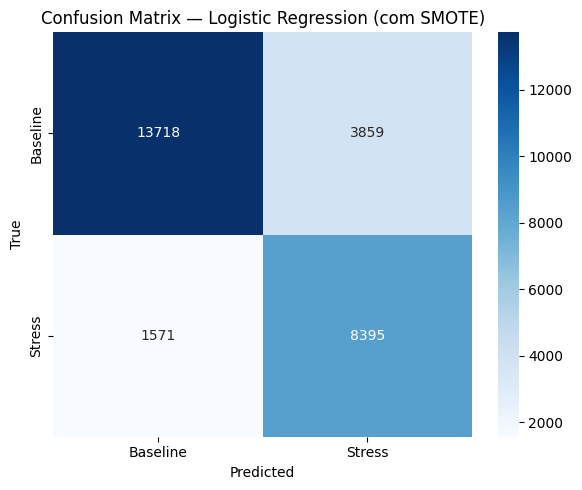

In [5]:
print("\n" + "="*50)
print("AVALIAÇÃO FINAL DETALHADA")
print("="*50)
print(classification_report(best_logreg['y_test'], best_logreg['y_pred']))
print(f"ROC-AUC:                      {best_logreg['roc_auc']:.3f}")
print(f"Balanced Accuracy:            {best_logreg['bal_acc']:.3f}")
print(f"Desvio Padrão F1 entre Folds: {best_logreg['f1_std']:.3f}")
print(f"\nMelhores parâmetros: {best_logreg['params']}")
print(f"Melhor F1:           {best_logreg['f1']:.3f}")
print(f"Accuracy:            {best_logreg['accuracy']:.3f}")
print(f"Recall:              {best_logreg['recall']:.3f}")

# Confusion Matrix
cm = best_logreg['cm']
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Baseline', 'Stress'],
            yticklabels=['Baseline', 'Stress'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix — Logistic Regression (com SMOTE)')
plt.tight_layout()
plt.show()

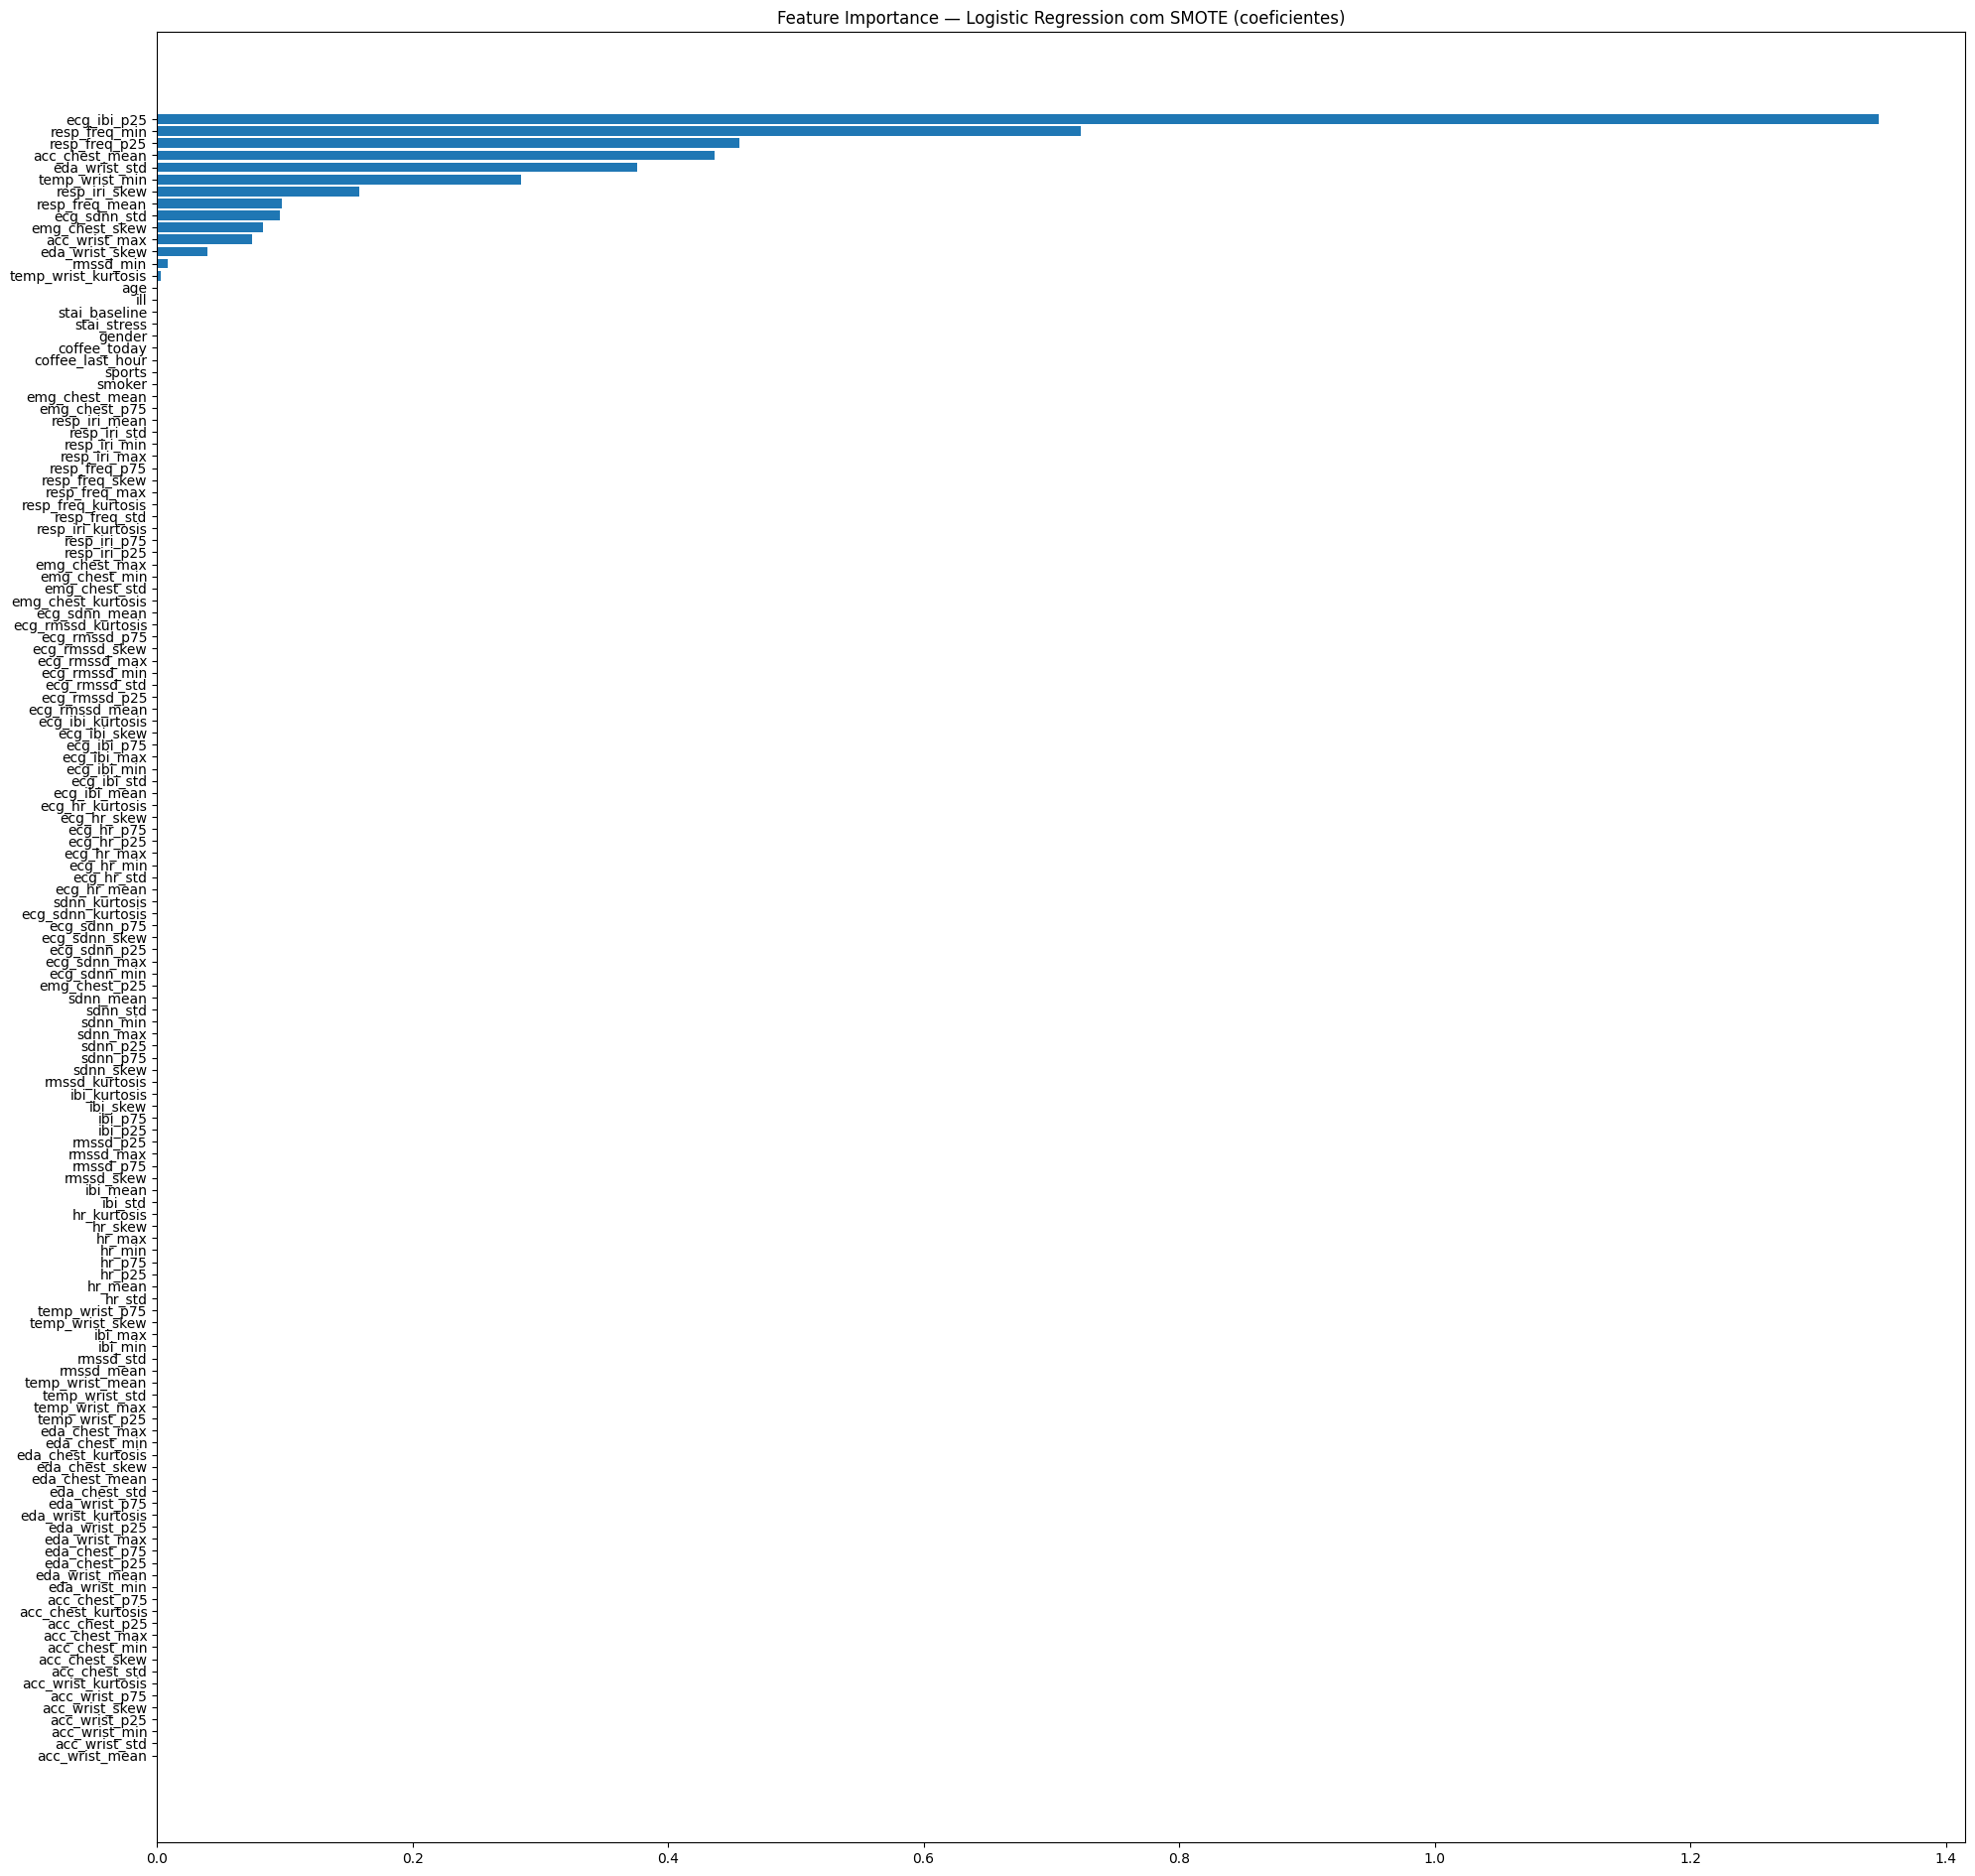

In [6]:
# Feature importance — modelo treinado em todos os dados
best_params = best_logreg['params']
model_params = {k: v for k, v in best_params.items()
                if not (k == 'l1_ratio' and best_params.get('penalty') != 'elasticnet')}

scaler  = StandardScaler()
imputer = SimpleImputer(strategy='median')
X_all = scaler.fit_transform(X_vals)
X_all = imputer.fit_transform(X_all)

smote = SMOTE(random_state=42)
X_sm, y_sm = smote.fit_resample(X_all, y_vals)

model = LogisticRegression(**model_params)
model.fit(X_sm, y_sm)

importances = np.abs(model.coef_[0])
indices = np.argsort(importances)

plt.figure(figsize=(20, 19))
plt.barh(np.array(feature_cols)[indices], importances[indices])
plt.title("Feature Importance — Logistic Regression com SMOTE (coeficientes)")
plt.tight_layout()
plt.show()

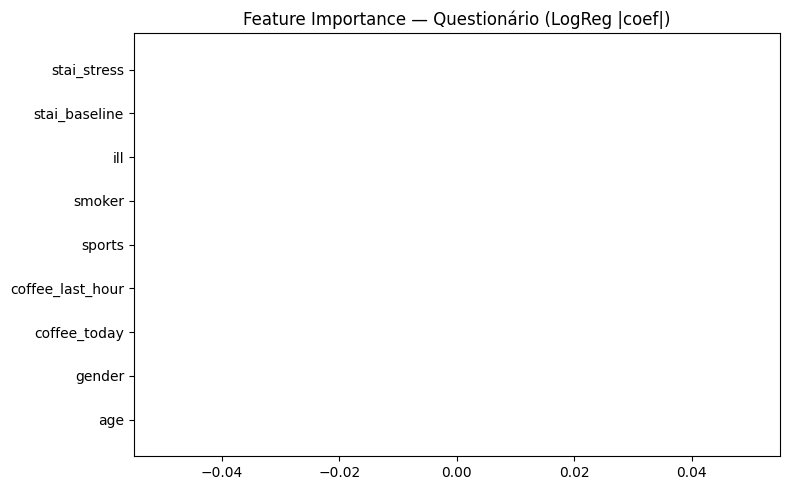

In [7]:
quest_cols = ['age', 'gender', 'coffee_today', 'coffee_last_hour',
              'sports', 'smoker', 'ill', 'stai_baseline', 'stai_stress']
quest_indices = [list(feature_cols).index(c) for c in quest_cols]
quest_importances = importances[quest_indices]
indices_q = np.argsort(quest_importances)

plt.figure(figsize=(8, 5))
plt.barh(np.array(quest_cols)[indices_q], quest_importances[indices_q])
plt.title("Feature Importance — Questionário (LogReg |coef|)")
plt.tight_layout()
plt.show()

In [8]:
os.makedirs('/kaggle/working/roc_data', exist_ok=True)
roc_data = {
    'y_test':  best_logreg['y_test'],
    'y_pred':  best_logreg['y_pred'],
    'y_prob':  best_logreg['y_prob'],
    'roc_auc': best_logreg['roc_auc'],
    'model':   'LogReg',
    'smote':   True,
}
with open('/kaggle/working/roc_data/logreg_smote.pkl', 'wb') as f:
    pickle.dump(roc_data, f)
print("ROC data guardado.")

ROC data guardado.
